<a href="https://colab.research.google.com/github/takumi-maker/dmd/blob/main/DMD_boostrap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import math
import statistics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
import matplotlib.pyplot as plt
from scipy.linalg import svd
import warnings

In [ ]:
a=np.array([[1,2,3]])
b=np.array([[2,3,4]])
c =b-a
print(c)

[[1 1 1]]


In [ ]:
df_1 = pd.read_csv("債券複利データセット3.csv")
df_1 = df_1.drop(df_1.columns[0], axis=1)
columns_len = len(df_1.columns)
length = len(df_1)
df_1
y_df = df_1
y_df = y_df.drop('GJGC7',axis=1)
y_df = y_df.drop('GJGC2',axis=1)
y_df = y_df.drop('GJGC5',axis=1)
y_df = y_df.drop('GJGC10',axis=1)
y_df = y_df.drop('GJGC15',axis=1)
y_df = y_df.drop('GJGC20',axis=1)
#y_df = y_df.drop('GJGC30',axis=1)
#y_df = y_df.drop('GJGC40',axis=1)
y_df

,GJGC30,GJGC40
0,0.649,0.666
1,0.635,0.649
2,0.643,0.661
3,0.649,0.670
4,0.658,0.679
...,...,...
1107,3.022,3.312
1108,3.061,3.372
1109,3.034,3.331
1110,3.006,3.293


<Axes: >

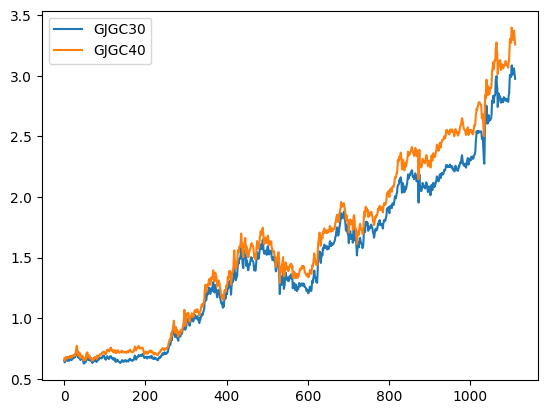

In [ ]:
y_df.plot()

In [ ]:


class DynamicModeDecomposition:
    def __init__(self, rank=None, svd_rank=None,T=None):
        """
        動的モード分解（DMD）クラス
        論文 "Dynamic mode decomposition of numerical and experimental data" に基づく実装

        Parameters:
        rank: DMDで使用するランク（Noneの場合は自動決定）
        svd_rank: SVDで使用するランク（Noneの場合は自動決定）
        """
        self.rank = rank
        self.svd_rank = svd_rank
        self.modes = None
        self.eigenvalues = None
        self.amplitudes = None
        self.Phi = None  # DMDモード
        self.omega = None  # 連続時間固有値
        self.b = None  # 初期振幅
        self.A_tilde = None  # 低次元線形演算子
        self.T = T

    def fit(self, X, dt=1.0):
        """
        DMDアルゴリズムを実行

        Parameters:
        X: データ行列 (n_features x n_timesteps)
        dt: 時間刻み
        """
        # Step 1: データをX1とX2に分割
        X1 = X[:, :-1]  # x_1, x_2, ..., x_{m-1}
        X2 = X[:, 1:]   # x_2, x_3, ..., x_m

        # Step 2: X1のSVD分解
        U, s, Vt = svd(X1, full_matrices=False)

        # Step 3: ランクの決定とtruncation
        if self.svd_rank is None:
            # 特異値の閾値による自動ランク決定
            tolerance = 1e-10
            self.svd_rank = np.sum(s > tolerance)

        r = min(self.svd_rank, len(s))
        U_r = U[:, :r]
        s_r = s[:r]
        V_r = Vt[:r, :].T

        # Step 4: 低次元線形演算子A_tildeの計算
        self.A_tilde = U_r.T @ X2 @ V_r @ np.diag(1/s_r)
        #self.A_tilde = U_r.T @ X2 @ V_r @ np.linalg.pinv(s_r)

        # Step 5: A_tildeの固有値分解
        eigenvals, W = np.linalg.eig(self.A_tilde)

        # Step 6: DMDモードの計算
        self.Phi = X2 @ V_r @ np.diag(1/s_r) @ W
        #self.Phi = X2 @ V_r @ np.linalg.pinv(s_r) @ W

        # 離散時間固有値
        self.eigenvalues = eigenvals

        # 連続時間固有値（論文の式に基づく）
        #self.omega = np.log(eigenvals) / dt
        self.omega = eigenvals #dt=1の場合 expがpredictのところで入れていないためlog入れていない

        # Step 7: 初期振幅の計算
        self.b = np.linalg.pinv(self.Phi) @ X[:, 0]

        # 使用するモード数の決定
        if self.rank is None:
            self.rank = r
        else:
            self.rank = min(self.rank, r)

        return self

    def predict(self, t_eval, x0=None):
        """
        指定された時刻での状態を予測

        Parameters:
        t_eval: 評価時刻
        x0: 初期条件（Noneの場合は学習データの初期条件を使用）

        Returns:
        X_pred: 予測された状態 (n_features )
        """
        if self.Phi is None:
            raise ValueError("まずfit()を実行してください")

        if x0 is not None:
            # 新しい初期条件での振幅計算
            b = np.linalg.pinv(self.Phi) @ x0
        else:
            b = self.b
        t_ = self.T + t_eval

        # 時間発展の計算
        # x(t) = Φ * diag(b) * exp(ω*t)

        time_evolution = np.array(self.omega[:self.rank, np.newaxis] **t_)

        # 予測
        X_pred = self.Phi[:, :self.rank] @ (b[:self.rank, np.newaxis] * time_evolution)

        return X_pred

    def compute_dmd_solution(self, t_eval, mode_indices=None):
        """
        特定のモードのみを使用したDMD解を計算

        Parameters:
        t_eval: 評価時刻
        mode_indices: 使用するモードのインデックス（Noneの場合は全モード）
        """
        if mode_indices is None:
            mode_indices = range(self.rank)

        time_evolution = np.exp(np.outer(self.omega[mode_indices], t_eval))
        X_dmd = self.Phi[:, mode_indices] @ (self.b[mode_indices, np.newaxis] * time_evolution)

        return X_dmd

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def evaluate_drawdown_block_bootstrap(historical_returns, current_drawdown, block_size=5, n_simulations=10000, confidence_level=0.95):
    """
    ブロック・ブートストラップ法によるドローダウン評価
    historical_returns: 戦略がワークしていた期間のリターンの配列 (np.array)
    current_drawdown: 現在直面しているドローダウンの絶対値 (正の値)
    block_size: 連続して抽出する日数の塊（例：5なら1週間分ずつ抽出）
    """
    returns = np.array(historical_returns)
    n_periods = len(returns)

    # データ数がブロックサイズより小さい場合のフェイルセーフ
    if n_periods < block_size:
        block_size = max(1, n_periods // 2)

    print(f"シミュレーション回数: {n_simulations}回, 期間: {n_periods}ステップ, ブロックサイズ: {block_size}")

    # 1. ブロック・ブートストラップによる仮想パス生成
    np.random.seed(42)

    # 必要なブロック数を計算（余分に引いて後で切り捨てる）
    n_blocks = int(np.ceil(n_periods / block_size))

    # 抽出可能なブロックの開始インデックスの最大値
    max_start_idx = n_periods - block_size

    # ランダムにブロックの開始位置を抽出 (shape: n_simulations x n_blocks)
    start_indices = np.random.randint(0, max_start_idx + 1, size=(n_simulations, n_blocks))

    # ブロック内の連番オフセットを作成 [0, 1, 2, ..., block_size-1]
    offsets = np.arange(block_size)

    # 各ブロックの全インデックスを展開 (shape: n_simulations x n_blocks x block_size)
    block_indices = start_indices[:, :, np.newaxis] + offsets

    # 元データからインデックスを使ってリターンを抽出
    simulated_returns = returns[block_indices]

    # 2D配列に平坦化し、元の配列の長さに切り揃える (shape: n_simulations x n_periods)
    simulated_returns = simulated_returns.reshape(n_simulations, -1)[:, :n_periods]

    # 2. 各パスの累積リターン（エクイティカーブ）を計算
    simulated_equity = np.cumsum(simulated_returns, axis=1)

    # 3. 各パスの最大ドローダウンを計算
    running_max = np.maximum.accumulate(simulated_equity, axis=1)
    drawdowns = running_max - simulated_equity
    max_drawdowns = np.max(drawdowns, axis=1)

    # 4. 統計的閾値の計算 (95%タイル＝ワースト5%ライン)
    threshold_95 = np.percentile(max_drawdowns, confidence_level * 100)
    threshold_99 = np.percentile(max_drawdowns, 99.0)

    # 可視化
    plt.figure(figsize=(10, 6))
    plt.hist(max_drawdowns, bins=50, alpha=0.7, color='blue', edgecolor='black')
    plt.axvline(threshold_95, color='orange', linestyle='dashed', linewidth=2, label=f'95% Threshold (p=0.05): {threshold_95:.4f}')
    plt.axvline(threshold_99, color='red', linestyle='dashed', linewidth=2, label=f'99% Threshold (p=0.01): {threshold_99:.4f}')
    plt.axvline(current_drawdown, color='black', linewidth=3, label=f'Current Actual DD: {current_drawdown:.4f}')

    plt.title(f'Block Bootstrap (Block Size: {block_size}) Dist of Max Drawdowns')
    plt.xlabel('Maximum Drawdown (Absolute Value)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 判定
    p_value = np.sum(max_drawdowns >= current_drawdown) / n_simulations
    print("-" * 50)
    print(f"過去分布から想定される95%ワーストDD: {threshold_95:.4f}")
    print(f"現在のドローダウン: {current_drawdown:.4f}")
    print(f"p値 (現在のDD以上のアクシデントが偶然起きる確率): {p_value:.4f} ({p_value*100:.2f}%)")

    if p_value < (1 - confidence_level):
        print("【結論】 確率的なブレの範囲を超えています。レジームシフト、または過学習の可能性が極めて高いです。")
    else:
        print("【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。")

# --- 実行例 ---
# block_size は戦略の平均保有期間や市場の局所的トレンドの長さに合わせます
# 例: 5 (1週間), 10 (2週間), 20 (1ヶ月)
# evaluate_drawdown_block_bootstrap(historical_returns, current_dd, block_size=10)

100
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_point2: 873
change_point2: 874
change_point: 875
change_point: 890
change_point: 892
change_point: 894
change_point2: 897
change_point2: 905
change_point2: 906
change_point2: 919
change_point: 920
change_point: 923
change_point: 924
change_point: 928
change_point: 929
change_point: 932
SharpRatio: 0.18746399493104207
0.890000000000001
0.09200000000000035
0.9820000000000013
シミュレーション回数: 10000回, 期間: 100ステップ, ブロックサイズ: 20


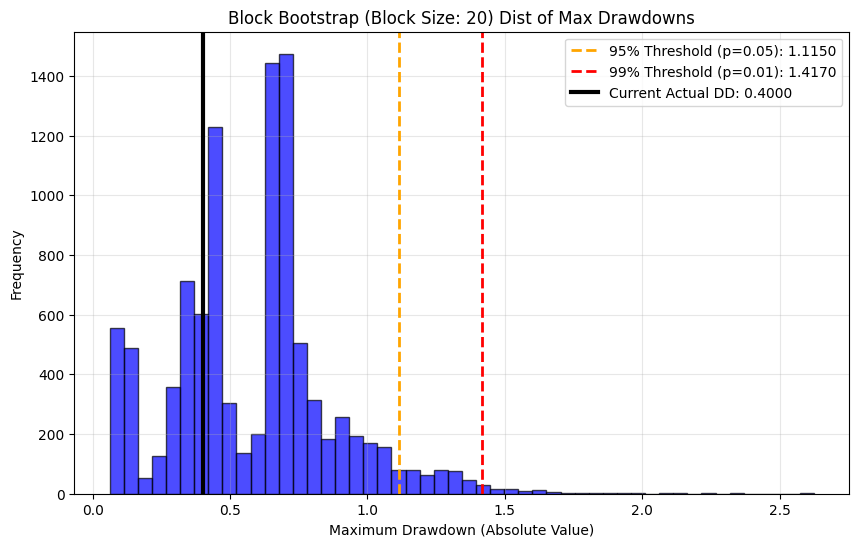

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.1150
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.7312 (73.12%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
200
change_point: 742
change_point: 744
change_point: 803
change_point: 804
change_point2: 828
change_point2: 830
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_point2: 873
change_point2: 874
change_point: 875
change_point: 890
change_point: 892
change_point: 894
change_point2: 897
change_point2: 905
change_point2: 906
change_point2: 919
change_point: 920
change_point: 923
change_point: 924
change_point: 928
change_point: 929
change_point: 932
SharpRatio: 0.17151648382602833
1.2150000000000012
0.3370000000000004
1.5520000000000016
シミュレーション回数: 10000回, 期間: 200ステップ, ブロックサイズ: 20


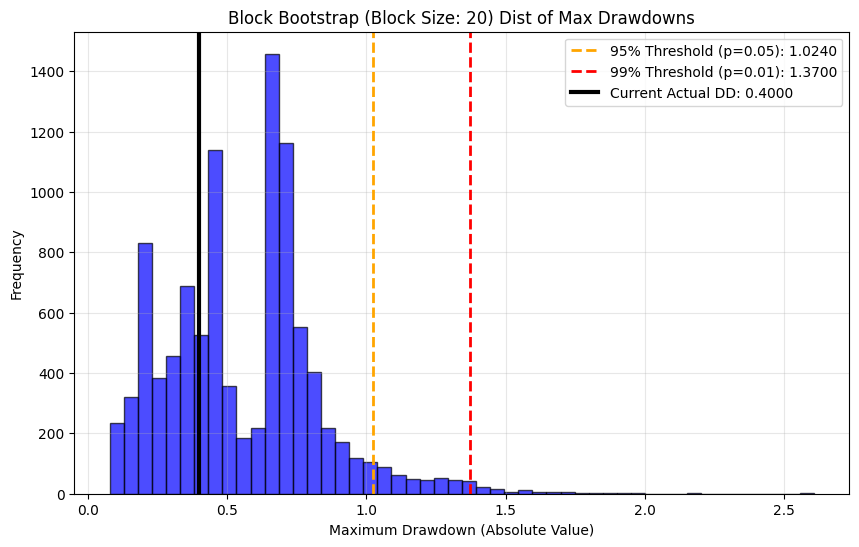

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.0240
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.6864 (68.64%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
300
change_point: 637
change_point2: 641
change_point2: 654
change_point2: 656
change_point2: 657
change_point2: 668
change_point2: 690
change_point2: 692
change_point2: 693
change_point: 694
change_point: 697
change_point: 698
change_point: 742
change_point: 744
change_point: 803
change_point: 804
change_point2: 828
change_point2: 830
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_point2: 873
change_point2: 874
change_point: 875
change_point: 890
change_point: 892
change_point: 894
change_point2: 897
change_point2: 905
change_point2: 906
change_point2: 919
change_point: 920
change_point: 923
change_point: 924
change_point: 928
change_point: 929
change_point: 932
SharpRatio: 0.1252589857856587
1.3179999999999998
0.534
1.8519999999999999
シミュレーション回数: 

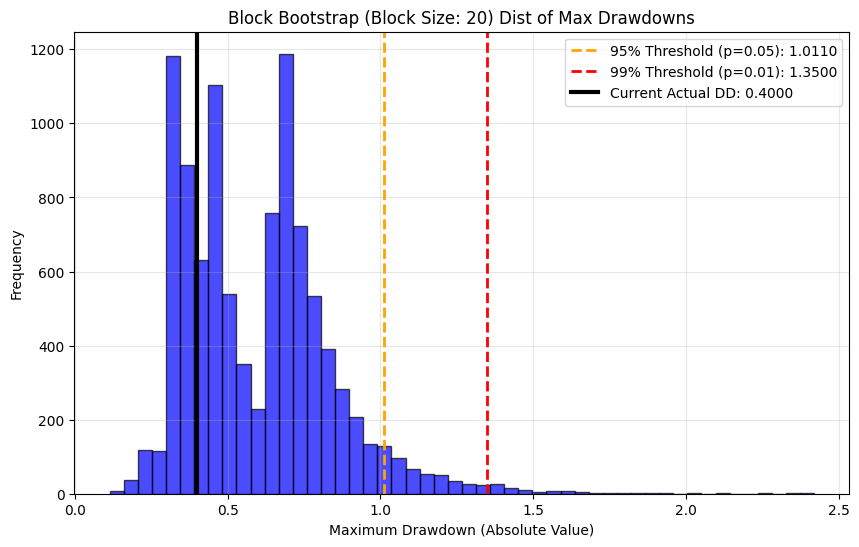

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.0110
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.7500 (75.00%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
400
change_point2: 536
change_point2: 537
change_point: 637
change_point2: 641
change_point2: 654
change_point2: 656
change_point2: 657
change_point2: 668
change_point2: 690
change_point2: 692
change_point2: 693
change_point: 694
change_point: 697
change_point: 698
change_point: 742
change_point: 744
change_point: 803
change_point: 804
change_point2: 828
change_point2: 830
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_point2: 873
change_point2: 874
change_point: 875
change_point: 890
change_point: 892
change_point: 894
change_point2: 897
change_point2: 905
change_point2: 906
change_point2: 919
change_point: 920
change_point: 923
change_point: 924
change_point: 928
change_point: 929
change_point: 932
SharpRatio: 0.1224421473435579
1.628
0.9069999999

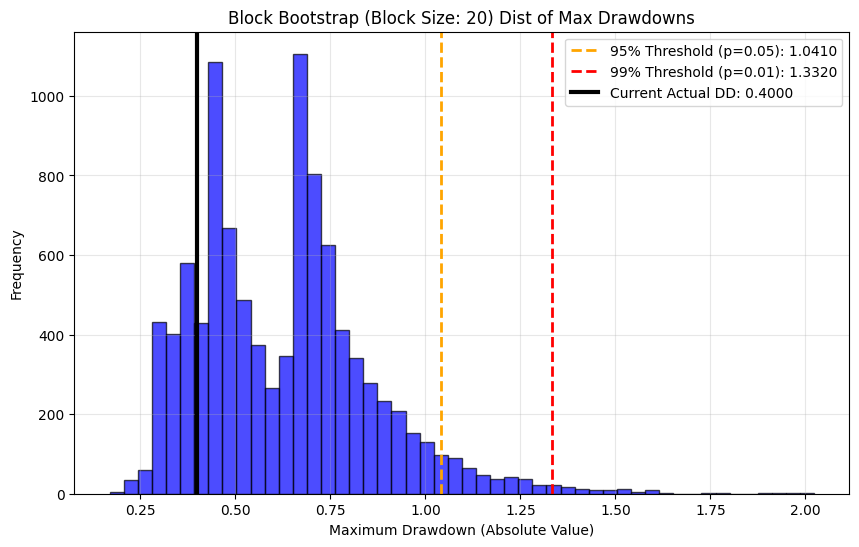

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.0410
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.8384 (83.84%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
500
change_point2: 492
change_point2: 496
change_point2: 499
change_point: 500
change_point: 501
change_point: 502
change_point: 515
change_point2: 521
change_point2: 536
change_point2: 537
change_point: 637
change_point2: 641
change_point2: 654
change_point2: 656
change_point2: 657
change_point2: 668
change_point2: 690
change_point2: 692
change_point2: 693
change_point: 694
change_point: 697
change_point: 698
change_point: 742
change_point: 744
change_point: 803
change_point: 804
change_point2: 828
change_point2: 830
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_point2: 873
change_point2: 874
change_point: 875
change_point: 890
change_point: 892
change_point: 894
change_point2: 897
change_point2: 905
change_point2: 906
change_point2: 919
change_po

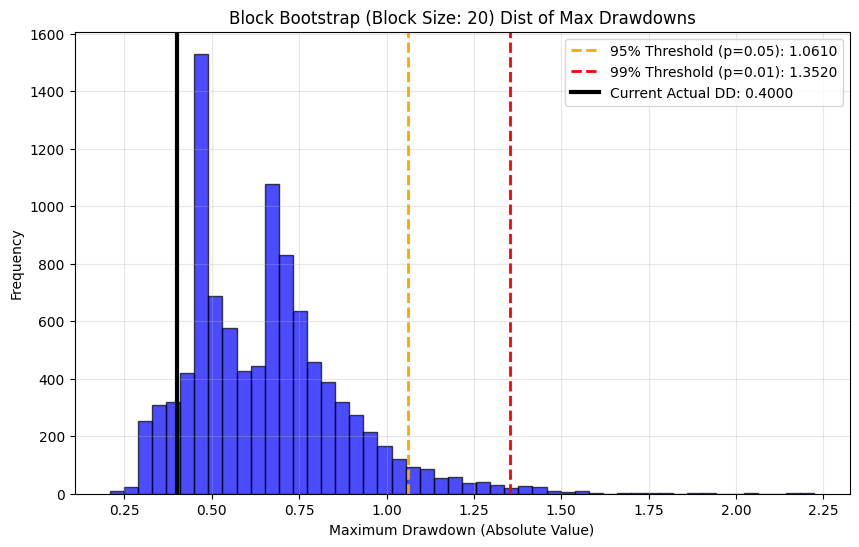

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.0610
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.9148 (91.48%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
600
change_point2: 492
change_point2: 496
change_point2: 499
change_point: 500
change_point: 501
change_point: 502
change_point: 515
change_point2: 521
change_point2: 536
change_point2: 537
change_point: 637
change_point2: 641
change_point2: 654
change_point2: 656
change_point2: 657
change_point2: 668
change_point2: 690
change_point2: 692
change_point2: 693
change_point: 694
change_point: 697
change_point: 698
change_point: 742
change_point: 744
change_point: 803
change_point: 804
change_point2: 828
change_point2: 830
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_point2: 873
change_point2: 874
change_point: 875
change_point: 890
change_point: 892
change_point: 894
change_point2: 897
change_point2: 905
change_point2: 906
change_point2: 919
change_po

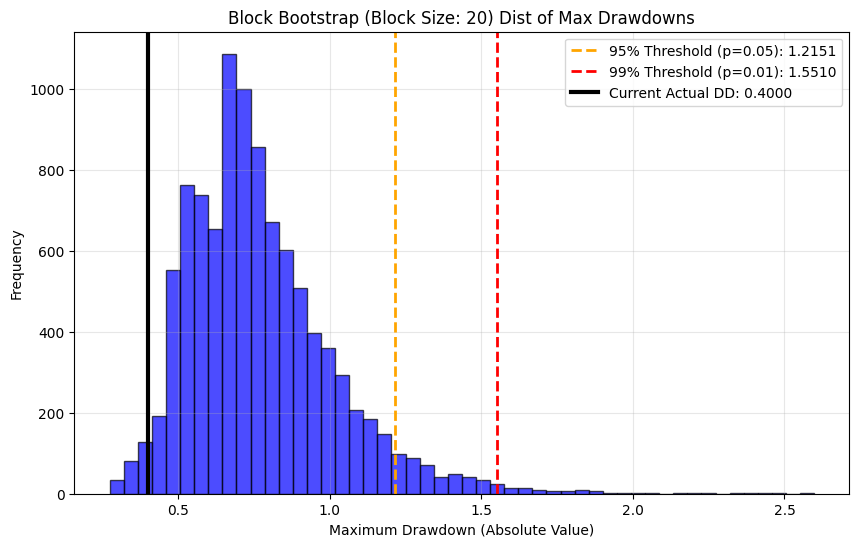

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.2151
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.9803 (98.03%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
700
change_point: 258
change_point2: 258
change_point: 259
change_point2: 259
change_point: 268
change_point2: 268
change_point: 269
change_point2: 269
change_point: 270
change_point: 271
change_point2: 492
change_point2: 496
change_point2: 499
change_point: 500
change_point: 501
change_point: 502
change_point: 515
change_point2: 521
change_point2: 536
change_point2: 537
change_point: 637
change_point2: 641
change_point2: 654
change_point2: 656
change_point2: 657
change_point2: 668
change_point2: 690
change_point2: 692
change_point2: 693
change_point: 694
change_point: 697
change_point: 698
change_point: 742
change_point: 744
change_point: 803
change_point: 804
change_point2: 828
change_point2: 830
change_point2: 836
change_point2: 856
change_point2: 858
change_point: 862
change_point: 864
change_poin

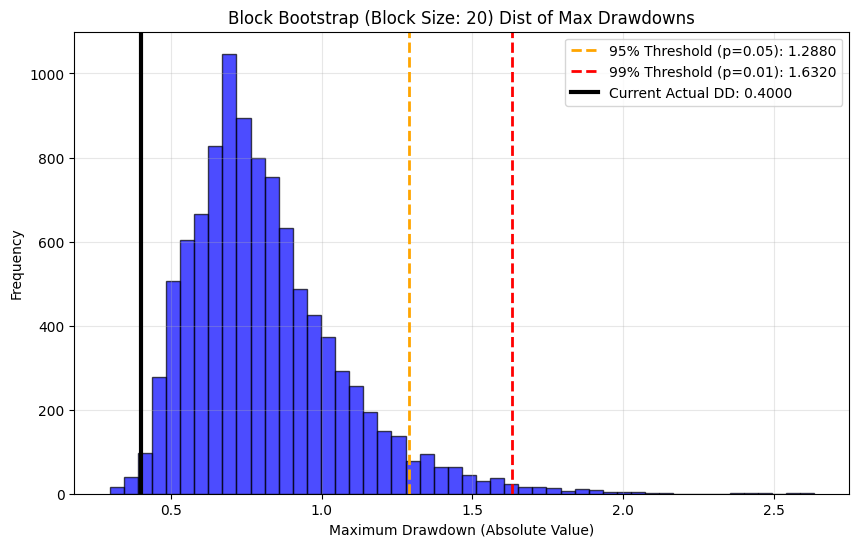

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.2880
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.9935 (99.35%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。
800
change_point2: 153
change_point: 154
change_point: 156
change_point2: 156
change_point2: 157
change_point2: 159
change_point2: 197
change_point: 198
change_point: 258
change_point2: 258
change_point: 259
change_point2: 259
change_point: 268
change_point2: 268
change_point: 269
change_point2: 269
change_point: 270
change_point: 271
change_point2: 492
change_point2: 496
change_point2: 499
change_point: 500
change_point: 501
change_point: 502
change_point: 515
change_point2: 521
change_point2: 536
change_point2: 537
change_point: 637
change_point2: 641
change_point2: 654
change_point2: 656
change_point2: 657
change_point2: 668
change_point2: 690
change_point2: 692
change_point2: 693
change_point: 694
change_point: 697
change_point: 698
change_point: 742
change_point: 744
change_point: 803
change_poin

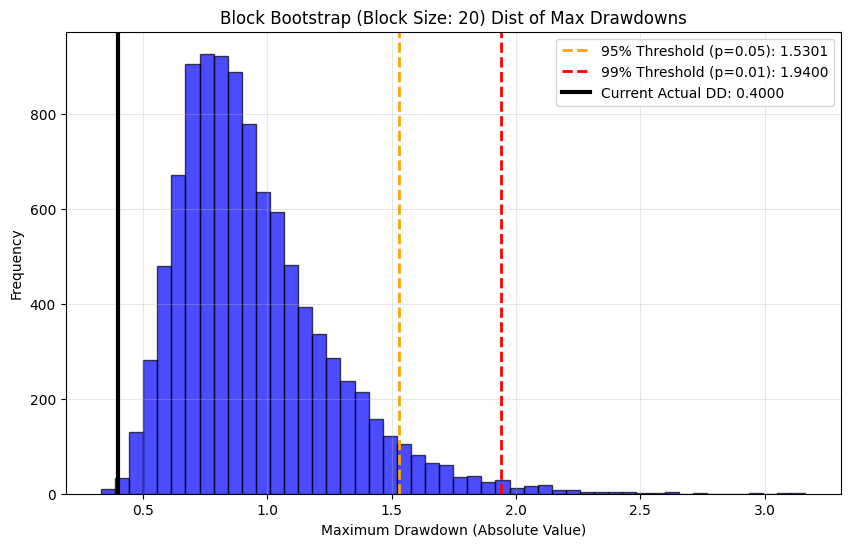

--------------------------------------------------
過去分布から想定される95%ワーストDD: 1.5301
現在のドローダウン: 0.4000
p値 (現在のDD以上のアクシデントが偶然起きる確率): 0.9987 (99.87%)
【結論】 確率的なドローダウンの範囲内（想定内）です。稼働継続は統計的に正当化されます。


In [ ]:
#15～40用
from sklearn.linear_model import LinearRegression
import statsmodels
import statsmodels.api
import matplotlib.pyplot as plt
from sklearn import preprocessing
import cvxpy as cp

magic_num = 180 #180
estimate_num = 150
predict_time = 1

df_array = y_df.to_numpy()


for i in range(1,9):
  total_num = 100*i
  print(total_num)

  total_list = []
  y_list = []
  current_list = []
  result_list = []
  result_list_2 = []
  predict_flag2 = 0
  predict_flag2_2 = 0
  for j in range(magic_num-1,len(df_array)):
    X_return_list = []
    for k in range(1,magic_num):
      X_return_list.append(df_array[j-k])
    y_return = (df_array[j]-df_array[j-1])*1
    current_list.append(df_array[j-1])
    y_list.append(y_return)
    X_list2 = list(reversed(X_return_list))
    total_list.append(X_list2)

  total_list = np.array(total_list)
  y_list = np.array(y_list)
  current_list = np.array(current_list)
  #print(total_list)
  #print(total_list.shape)
  #print(y_list.shape)
  for j in range(len(total_list)):
    if j <= len(total_list)-1-total_num:
      continue
    #print(j)
    X_array = np.array(total_list[j])
    y_array = y_list[j]
    current_X = np.array(current_list[j])
    #print(X_array.shape)
    #print(y_array.shape)
    #print("#")

    #この後Xを転置してDMDに突っ込む
    X_DMD = X_array.T
    dmd = DynamicModeDecomposition(rank=15, svd_rank=1,T=magic_num)

    dmd.fit(X_DMD)
    X_pred = dmd.predict(predict_time)
    #print(X_pred.real)

    y_pred = X_pred[0,0].real
    #print(y_pred
    current_y = current_X[0]
    retrun_ = y_array[0]

    y_pred_2 = X_pred[1,0].real
    #print(y_pred
    current_y_2 = current_X[1]
    retrun_2 = y_array[1]
    #print(current_y)

    if y_pred - current_y >= 0.0000:
      predict_flag = -1
    elif y_pred - current_y <-0.0000:
      predict_flag = 1
    else:
      predict_flag = predict_flag2

    if predict_flag*predict_flag2 >=0:
      result_r = retrun_*predict_flag
      result_list.append(result_r)
      predict_flag2 = predict_flag
    else:
      result_r = retrun_*predict_flag-0.01
      result_list.append(result_r)
      predict_flag2 = predict_flag
      print("change_point:",j)

    if y_pred_2 - current_y_2 >= 0.0000:
      predict_flag_2 = -1
    elif y_pred_2 - current_y_2 <-0.0000:
      predict_flag_2 = 1
    else:
      predict_flag_2 = predict_flag2_2

    if predict_flag_2*predict_flag2_2 >=0:
      result_r_2 = retrun_2*predict_flag_2
      result_list_2.append(result_r_2)
      predict_flag2_2 = predict_flag_2
    else:
      result_r_2 = retrun_2*predict_flag_2-0.01
      result_list_2.append(result_r_2)
      predict_flag2_2 = predict_flag_2
      print("change_point2:",j)

  R_sum = sum(result_list)
  R_sum2 = sum(result_list_2)
  result_combined = [x + y for x, y in zip(result_list, result_list_2)]
  SR = np.mean(np.array(result_list))/np.std(np.array(result_list))
  print("SharpRatio:",SR)
  print(R_sum)
  print(R_sum2)

  print(sum(result_combined))
  historical_returns = np.array(result_combined)
  current_dd = 0.40 # 現在抱えているドローダウンの幅を入力
  evaluate_drawdown_block_bootstrap(historical_returns, current_dd, block_size=20)

In [ ]:
SR_list = [-0.05,0.03,0.05,0.08,0.10,0.10,0.05]
print(np.std(SR_list))

0.048234122903240376


In [ ]:
import numpy as np
import scipy.stats as ss

def evaluate_multiple_testing_bias(actual_annualized_sr, n_trials, n_samples, skewness=0.0, kurtosis=5.0):
    """
    パラメータチューニングによる過学習（マルチプル・テスティング・バイアス）を検証する

    actual_annualized_sr: バックテストで得られた年率シャープレシオ（日次SR * √252）
    n_trials: 試行したパラメータ組み合わせの総数（大体の数でOK）
    n_samples: バックテストの期間（日次データなら日数）
    skewness: 日次リターンの歪度（通常は0でOK）
    kurtosis: 日次リターンの尖度（正規分布なら3。金融データは4〜5になりがち）
    """

    # 1. 独立したN回の試行から「まぐれ」で出る年率SRの期待最大値（ハードルレート）を計算
    # 極値理論（EVT）の近似公式を使用
    if n_trials < 2:
        expected_max_sr = 0.0
    else:
        emc = 0.5772156649 # オイラー・マスケローニ定数
        max_Z = (1 - emc) * ss.norm.ppf(1 - 1/n_trials) + emc * ss.norm.ppf(1 - 1/(n_trials * np.e))
        # ここでは試行した全モデルのSRの標準偏差を1.0(年率)と仮定
        expected_max_sr = max_Z * 0.9

    # 2. 確率的シャープレシオ (Probabilistic Sharpe Ratio: PSR) の計算
    # 実際のSRが、まぐれのハードルレートを統計的に有意に超えているかをテスト
    sr_diff = actual_annualized_sr - expected_max_sr

    # SRの分散（サンプル数、歪度、尖度から算出）
    sr_var = (1 - skewness * actual_annualized_sr + (kurtosis - 1) / 4 * actual_annualized_sr**2) / n_samples

    # PSR（実際のSRが期待最大SRを上回っている確率）
    psr = ss.norm.cdf(sr_diff / np.sqrt(sr_var))

    print("-" * 50)
    print(f"テストしたパラメータ組み合わせ数: 約 {n_trials} 通り")
    print(f"この回数テストすれば『まぐれ』でも出る年率SRの期待値: {expected_max_sr:.2f}")
    print(f"あなたの戦略の実際の年率SR: {actual_annualized_sr:.2f}")
    print(f"PSR (優位性が本物である確率): {psr*100:.1f} %")

    if psr > 0.95:
        print("【結論】 過学習ではありません。このSRは試行回数を考慮しても統計的に本物です。")
    else:
        print("【結論】 過学習（カーブフィッティング）の可能性が高いです。偶然見つけたノイズであるリスクがあります。")

# --- 実行例 ---
# 画面を拝見すると日次SRが0.08程度のようなので、年率換算(0.08 * √252)で約1.27とします。
# 試行したパラメータ数が「50通り」だったと仮定して実行します。
evaluate_multiple_testing_bias(actual_annualized_sr=1.27, n_trials=10, n_samples=1000)

--------------------------------------------------
テストしたパラメータ組み合わせ数: 約 10 通り
この回数テストすれば『まぐれ』でも出る年率SRの期待値: 1.42
あなたの戦略の実際の年率SR: 1.27
PSR (優位性が本物である確率): 0.2 %
【結論】 過学習（カーブフィッティング）の可能性が高いです。偶然見つけたノイズであるリスクがあります。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_dmd_regime_shift(X_past, X_recent, dmd_rank=3):
    """
    過去と直近のデータ行列をDMDで比較し、レジームシフトを可視化する
    X_past: 戦略が機能していた期間のデータ行列 (n_features x n_timesteps)
    X_recent: 直近の不調期間のデータ行列 (n_features x n_timesteps)
    """

    # --- 1. DMDの実行 ---
    dmd_past = DynamicModeDecomposition(rank=dmd_rank)
    dmd_past.fit(X_past)

    dmd_recent = DynamicModeDecomposition(rank=dmd_rank)
    dmd_recent.fit(X_recent)

    # 振幅(b)の絶対値が大きい順にモードを並び替える（影響力の強い順）
    idx_past = np.argsort(np.abs(dmd_past.b))[::-1][:dmd_rank]
    idx_recent = np.argsort(np.abs(dmd_recent.b))[::-1][:dmd_rank]

    # データの抽出とソート
    phi_past = dmd_past.Phi[:, idx_past]
    phi_recent = dmd_recent.Phi[:, idx_recent]

    omega_past = dmd_past.omega[idx_past]
    omega_recent = dmd_recent.omega[idx_recent]

    b_past = np.abs(dmd_past.b[idx_past])
    b_recent = np.abs(dmd_recent.b[idx_recent])

    # --- 可視化 ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. 固有値の比較 (複素平面 / 単位円)
    ax = axes[0]
    theta = np.linspace(0, 2*np.pi, 100)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.3, label='Unit Circle')

    ax.scatter(omega_past.real, omega_past.imag, s=100, c='blue', alpha=0.7, label='Past Window')
    ax.scatter(omega_recent.real, omega_recent.imag, s=100, c='red', marker='X', alpha=0.7, label='Recent Window')

    ax.set_title('1. Eigenvalues (Dynamics Shift)')
    ax.set_xlabel('Real')
    ax.set_ylabel('Imaginary')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 2. 影響力(振幅)の比較
    ax = axes[1]
    x_labels = [f'Mode {i+1}' for i in range(dmd_rank)]
    width = 0.35
    x = np.arange(dmd_rank)

    # 正規化して比較（全体に対するエネルギー割合）
    b_past_norm = b_past / np.sum(b_past)
    b_recent_norm = b_recent / np.sum(b_recent)

    ax.bar(x - width/2, b_past_norm, width, label='Past', color='blue', alpha=0.7)
    ax.bar(x + width/2, b_recent_norm, width, label='Recent', color='red', alpha=0.7)

    ax.set_title('2. Mode Amplitudes (Energy Shift)')
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels)
    ax.set_ylabel('Normalized Amplitude')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

    # 3. 空間モード(Phi)の類似度 (MAC行列)
    ax = axes[2]
    mac_matrix = np.zeros((dmd_rank, dmd_rank))

    for i in range(dmd_rank):
        for j in range(dmd_rank):
            # MAC (Modal Assurance Criterion) の計算: 0〜1の値をとり、1なら完全に同じ形状
            num = np.abs(np.vdot(phi_past[:, i], phi_recent[:, j]))**2
            den = (np.linalg.norm(phi_past[:, i])**2) * (np.linalg.norm(phi_recent[:, j])**2)
            mac_matrix[i, j] = num / den

    sns.heatmap(mac_matrix, annot=True, cmap='Blues', vmin=0, vmax=1, ax=ax,
                xticklabels=[f'Recent {i+1}' for i in range(dmd_rank)],
                yticklabels=[f'Past {i+1}' for i in range(dmd_rank)])
    ax.set_title('3. Spatial Mode Similarity (MAC)')
    ax.set_xlabel('Recent Modes')
    ax.set_ylabel('Past Modes')

    plt.tight_layout()
    plt.show()

# --- 実行例 ---
# X_past: 過去のうまくいっていた期間のデータを転置したもの (例: 前半500日)
# X_recent: 直近の不調な期間のデータを転置したもの (例: 直近100日)
# X_past = df_array[:500].T
# X_recent = df_array[-100:].T
# analyze_dmd_regime_shift(X_past, X_recent, dmd_rank=3)

In [ ]:
#移動平均考慮バージョン
from sklearn.linear_model import LinearRegression
import statsmodels
import statsmodels.api
import matplotlib.pyplot as plt
from sklearn import preprocessing
import cvxpy as cp

magic_num = 180
estimate_num = 150
mean_num = 7
predict_time = 1

df_array = y_df.to_numpy()


for i in range(1,8):
  total_num = 100*i
  print(total_num)

  total_list = []
  y_list = []
  current_list = []
  result_list = []
  predict_flag = 0
  predict_flag2 = 0
  for j in range(magic_num-1,len(df_array)):
    X_return_list = []
    for k in range(1,magic_num):
      X_return_list.append(df_array[j-k])
    y_return = (df_array[j]-df_array[j-1])*1
    current_list.append(df_array[j-1])
    y_list.append(y_return)
    X_list2 = list(reversed(X_return_list))
    total_list.append(X_list2)

  total_list = np.array(total_list)
  y_list = np.array(y_list)
  current_list = np.array(current_list)
  #print(total_list)
  #print(total_list.shape)
  #print(y_list.shape)
  for j in range(len(total_list)):
    if j <= len(total_list)-1-total_num:
      continue
    #print(j+magic_num-1)
    X_array = np.array(total_list[j])
    #print(X_array)
    mean_list = []
    for l in range(len(X_array)-mean_num,len(X_array)):
      mean_list.append(X_array[l][1])#二番目を変える

    y_array = y_list[j]
    current_X = np.array(current_list[j])
    mean_X = np.mean(np.array(mean_list))
    #print(mean_list)
    #print(mean_X)
    #print(X_array.shape)
    #print(y_array.shape)
    #print("#")

    #この後Xを転置してDMDに突っ込む
    X_DMD = X_array.T
    dmd = DynamicModeDecomposition(rank=15, svd_rank=1,T=magic_num)

    dmd.fit(X_DMD)
    X_pred = dmd.predict(predict_time)
    #print(X_pred.real)

    y_pred = X_pred[1,0].real
    #print(y_pred
    current_y = current_X[1]
    retrun_ = y_array[1]
    #print(current_y)

    if y_pred - current_y >= 0.0000:
      if mean_X > current_y:
        predict_flag = -1
    elif y_pred - current_y <-0.0000:
      if mean_X < current_y:
        predict_flag = 1
    else:
      predict_flag = 0

    if predict_flag==predict_flag2:
      result_r = retrun_*predict_flag
      result_list.append(result_r)
      predict_flag2 = predict_flag
    else:
      result_r = retrun_*predict_flag-0.01
      result_list.append(result_r)
      predict_flag2 = predict_flag
      print("change_point:",j)

  R_sum = sum(result_list)
  SR = np.mean(np.array(result_list))/np.std(np.array(result_list))
  print("SharpRatio:",SR)
  print(R_sum)

100
change_point: 842
change_point: 860
SharpRatio: 0.1089613936563505
0.3939999999999999
200
change_point: 733
change_point: 812
change_point: 860
SharpRatio: 0.08301434100316987
0.4999999999999999
300
change_point: 634
change_point: 690
change_point: 700
change_point: 812
change_point: 860
SharpRatio: 0.08626610370489475
0.7869999999999998
400
change_point: 534
change_point: 690
change_point: 700
change_point: 812
change_point: 860
SharpRatio: 0.08477232930185764
0.9609999999999997
500
change_point: 433
change_point: 513
change_point: 525
change_point: 690
change_point: 700
change_point: 812
change_point: 860
SharpRatio: 0.0947519987617959
1.2939999999999985
600
change_point: 333
change_point: 513
change_point: 525
change_point: 690
change_point: 700
change_point: 812
change_point: 860
SharpRatio: 0.08003836053789865
1.2330000000000003
700
change_point: 233
change_point: 513
change_point: 525
change_point: 690
change_point: 700
change_point: 812
change_point: 860
SharpRatio: 0.079677

In [ ]:
#移動平均考慮バージョンDMDなしバージョン
from sklearn.linear_model import LinearRegression
import statsmodels
import statsmodels.api
import matplotlib.pyplot as plt
from sklearn import preprocessing
import cvxpy as cp

magic_num = 180
estimate_num = 150
mean_num = 60
predict_time = 1

df_array = y_df.to_numpy()


for i in range(1,8):
  total_num = 100*i
  print(total_num)

  total_list = []
  y_list = []
  current_list = []
  result_list = []
  predict_flag = 0
  predict_flag2 = 0
  for j in range(magic_num-1,len(df_array)):
    X_return_list = []
    for k in range(1,magic_num):
      X_return_list.append(df_array[j-k])
    y_return = (df_array[j]-df_array[j-1])*1
    current_list.append(df_array[j-1])
    y_list.append(y_return)
    X_list2 = list(reversed(X_return_list))
    total_list.append(X_list2)

  total_list = np.array(total_list)
  y_list = np.array(y_list)
  current_list = np.array(current_list)
  #print(total_list)
  #print(total_list.shape)
  #print(y_list.shape)
  for j in range(len(total_list)):
    if j <= len(total_list)-1-total_num:
      continue
    #print(j+magic_num-1)
    X_array = np.array(total_list[j])
    #print(X_array)
    mean_list = []
    for l in range(len(X_array)-mean_num,len(X_array)):
      mean_list.append(X_array[l][0])#二番目を変える

    y_array = y_list[j]
    current_X = np.array(current_list[j])
    mean_X = np.mean(np.array(mean_list))
    #print(mean_list)
    #print(mean_X)
    #print(X_array.shape)
    #print(y_array.shape)
    #print("#")

    #この後Xを転置してDMDに突っ込む
    X_DMD = X_array.T
    dmd = DynamicModeDecomposition(rank=15, svd_rank=1,T=magic_num)

    dmd.fit(X_DMD)
    X_pred = dmd.predict(predict_time)
    #print(X_pred.real)

    y_pred = X_pred[0,0].real
    #print(y_pred
    current_y = current_X[0]
    retrun_ = y_array[0]
    #print(current_y)


    if mean_X > current_y:
      predict_flag = -1
    elif mean_X < current_y:
      predict_flag = 1
    else:
      predict_flag = 0

    if predict_flag==predict_flag2:
      result_r = retrun_*predict_flag
      result_list.append(result_r)
      predict_flag2 = predict_flag
    else:
      result_r = retrun_*predict_flag-0.0
      result_list.append(result_r)
      predict_flag2 = predict_flag
      print("change_point:",j)

  R_sum = sum(result_list)
  SR = np.mean(np.array(result_list))/np.std(np.array(result_list))
  print("SharpRatio:",SR)
  print(R_sum)

100
change_point: 833
change_point: 855
change_point: 880
change_point: 903
change_point: 904
SharpRatio: -0.004569375727819085
-0.019000000000000128
200
change_point: 733
change_point: 737
change_point: 855
change_point: 880
change_point: 903
change_point: 904
SharpRatio: 0.06046398489972718
0.3979999999999998
300
change_point: 633
change_point: 661
change_point: 664
change_point: 694
change_point: 737
change_point: 855
change_point: 880
change_point: 903
change_point: 904
SharpRatio: 0.05629422919263504
0.5689999999999997
400
change_point: 533
change_point: 565
change_point: 566
change_point: 572
change_point: 573
change_point: 576
change_point: 661
change_point: 664
change_point: 694
change_point: 737
change_point: 855
change_point: 880
change_point: 903
change_point: 904
SharpRatio: 0.04482946364859339
0.5749999999999997
500
change_point: 433
change_point: 521
change_point: 565
change_point: 566
change_point: 572
change_point: 573
change_point: 576
change_point: 661
change_point: 6

In [ ]:
#2～10用先物が一番儲かる
from sklearn.linear_model import LinearRegression
import statsmodels
import statsmodels.api
import matplotlib.pyplot as plt
from sklearn import preprocessing
import cvxpy as cp

magic_num = 180
estimate_num = 150
predict_time = 1

df_array = y_df.to_numpy()


for i in range(1,8):
  total_num = 100*i
  print(total_num)

  total_list = []
  y_list = []
  current_list = []
  result_list = []
  predict_flag2 = 0
  for j in range(magic_num-1,len(df_array)):
    X_return_list = []
    for k in range(1,magic_num):
      X_return_list.append(df_array[j-k])
    y_return = (df_array[j]-df_array[j-1])*1
    current_list.append(df_array[j-1])
    y_list.append(y_return)
    X_list2 = list(reversed(X_return_list))
    total_list.append(X_list2)

  total_list = np.array(total_list)
  y_list = np.array(y_list)
  current_list = np.array(current_list)
  #print(total_list)
  #print(total_list.shape)
  #print(y_list.shape)
  for j in range(len(total_list)):
    if j <= len(total_list)-1-total_num:
      continue
    #print(j)
    X_array = np.array(total_list[j])
    y_array = y_list[j]
    current_X = np.array(current_list[j])
    #print(X_array.shape)
    #print(y_array.shape)
    #print("#")

    #この後Xを転置してDMDに突っ込む
    X_DMD = X_array.T
    dmd = DynamicModeDecomposition(rank=15, svd_rank=1,T=magic_num)

    dmd.fit(X_DMD)
    X_pred = dmd.predict(predict_time)
    #print(X_pred.real)

    y_pred = X_pred[0,0].real
    #print(y_pred
    current_y = current_X[0]
    retrun_ = y_array[0]
    #print(current_y)

    if y_pred - current_y >= 0.0000:
      predict_flag = -1
    elif y_pred - current_y <-0.0000:
      predict_flag = 1
    else:
      predict_flag = predict_flag2

    if predict_flag*predict_flag2 >=0:
      result_r = retrun_*predict_flag
      result_list.append(result_r)
      predict_flag2 = predict_flag
    else:
      result_r = retrun_*predict_flag-0.01
      result_list.append(result_r)
      predict_flag2 = predict_flag
      print("change_point:",j)

  R_sum = sum(result_list)
  SR = np.mean(np.array(result_list))/np.std(np.array(result_list))
  print("SharpRatio:",SR)
  print(R_sum)


100
change_point: 835
change_point: 852
change_point: 853
change_point: 854
SharpRatio: 0.02218335546896129
0.09300000000000003
200
change_point: 825
change_point: 829
change_point: 835
change_point: 852
change_point: 853
change_point: 854
SharpRatio: 0.11545698926700447
0.7619999999999999
300
change_point: 825
change_point: 829
change_point: 835
change_point: 852
change_point: 853
change_point: 854
SharpRatio: 0.07304254129663681
0.7409999999999999
400
change_point: 825
change_point: 829
change_point: 835
change_point: 852
change_point: 853
change_point: 854
SharpRatio: 0.0727287224177974
0.9349999999999998
500
change_point: 492
change_point: 495
change_point: 501
change_point: 515
change_point: 517
change_point: 518
change_point: 825
change_point: 829
change_point: 835
change_point: 852
change_point: 853
change_point: 854
SharpRatio: 0.0669977093681784
1.0539999999999998
600
change_point: 492
change_point: 495
change_point: 501
change_point: 515
change_point: 517
change_point: 518
ch

In [ ]:
from sklearn.linear_model import LinearRegression
import statsmodels
import statsmodels.api
import matplotlib.pyplot as plt
from sklearn import preprocessing
import cvxpy as cp

magic_num = 100
estimate_num = 150

df_array = y_df.to_numpy()


for i in range(1,8):
  total_num = 100*i
  print(total_num)

  total_list = []
  y_list = []
  result_list = []
  predict_flag2 = 0
  for j in range(magic_num-2,len(df_array)):
    X_return_list = []
    for k in range(1,magic_num):
      X_return_list.append(df_array[j-k])
    y_return = (df_array[j]-df_array[j-1])*1
    y_list.append(y_return)
    X_list2 = list(reversed(X_return_list))
    total_list.append(X_list2)
  print(total_list)

  for j in range(len(total_list)):
    if j <= len(total_list)-1-total_num:
      continue
    #print(j)
    X_array = np.array(total_list[j])
    y_array = y_list[j]
    #この後Xを転置してDMDに突っ込む




    #alpha = np.array([0,0.1,0.2,0.3,0.4,0.5])
    #print(estimate_list.shape)
    #print(estimate_y_list.shape)
    k= estimate_list.shape[1]
    beta = cp.Variable(k,nonneg=True)
    constraints =[beta[i] <= beta[i+1]*0.9 for i in range(k-1)]
    #error = cp.norm2(estimate_y_list - estimate_list @ beta)
    #objective =  cp.sum_squares(estimate_y_list - estimate_list @ beta)
    objective =  cp.norm2(estimate_y_list - estimate_list @ beta)
    #objective = cp.Minimize(error)


    #prob = cp.Problem(objective, constraints)
    #prob = cp.Problem(cp.Minimize(objective), constraints)
    prob = cp.Problem(cp.Minimize(objective))
    prob.solve()
    #print("status:", prob.status)
    #print("optimal value", prob.value)
    #print("optimal var", beta.value)

    predict = np.dot(X_array,beta.value)
    #print(predict)
    #print(y_array)

    if predict >= 0.0000:
      predict_flag = -1
    elif predict <-0.0000:
      predict_flag = 1
    else:
      predict_flag = predict_flag2

    if predict_flag*predict_flag2 >=0:
      result_r = y_array*predict_flag
      result_list.append(result_r)
      predict_flag2 = predict_flag
    else:
      result_r = y_array*predict_flag-0.005
      result_list.append(result_r)
      predict_flag2 = predict_flag

  R_sum = sum(result_list)
  SR = np.mean(np.array(result_list))/np.std(np.array(result_list))
  print("SharpRatio:",SR)
  print(R_sum)




100


KeyboardInterrupt: 

In [ ]:
# テストデータの生成
X, t, dt = create_test_data()

print("データ形状:", X.shape)
print("時間刻み:", dt)

# DMDの実行
dmd = DynamicModeDecomposition(rank=10, svd_rank=15)
dmd.fit(X, dt=dt)

# 予測
X_pred = dmd.predict(t)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
import warnings


In [ ]:
def create_test_data():
    """テスト用のデータを生成"""
    # 時間軸
    t = np.linspace(0, 10, 200)
    dt = t[1] - t[0]

    # 複数の動的モードを持つシステム
    # モード1: 減衰振動
    mode1 = np.exp(-0.1 * t) * np.sin(2 * np.pi * 0.5 * t)
    # モード2: 成長振動
    mode2 = np.exp(0.05 * t) * np.cos(2 * np.pi * 0.8 * t)
    # モード3: 純粋減衰
    mode3 = np.exp(-0.2 * t)

    # 空間構造を追加
    n_spatial = 50
    x_spatial = np.linspace(0, 1, n_spatial)

    # 各モードに異なる空間構造を与える
    spatial1 = np.sin(np.pi * x_spatial)
    spatial2 = np.sin(2 * np.pi * x_spatial)
    spatial3 = np.exp(-((x_spatial - 0.5) / 0.2)**2)  # ガウシアン

    # データ行列の構築
    X = (spatial1[:, np.newaxis] @ mode1[np.newaxis, :] +
         spatial2[:, np.newaxis] @ mode2[np.newaxis, :] +
         spatial3[:, np.newaxis] @ mode3[np.newaxis, :])

    # ノイズを追加
    noise_level = 0.05
    X += noise_level * np.random.randn(*X.shape)

    return X, t, dt

In [ ]:
X, t, dt = create_test_data()
print("データ形状:", X.shape)
#print("時間刻み:", dt)
print(X)

データ形状: (50, 200)
[[-0.0745888   0.05321973  0.01286006 ...  0.0273461   0.02968766
   0.0828189 ]
 [ 0.23515432  0.09822955  0.04070709 ...  0.13957109  0.24122071
   0.15837971]
 [ 0.28280217  0.21683989  0.28078008 ...  0.30791642  0.44357456
   0.44619883]
 ...
 [-0.30979545 -0.22805543 -0.18186889 ... -0.36120284 -0.48299688
  -0.38423087]
 [-0.193734   -0.13267655 -0.13453994 ... -0.10046946 -0.27859123
  -0.23440034]
 [ 0.00326939  0.10574404  0.02580776 ... -0.09704743 -0.0419091
  -0.01568088]]


In [ ]:
a=np.array([[1],[2],[3]])
b=np.array([[2],[3],[4]])
c =a*b
print(c)

[[ 2]
 [ 6]
 [12]]


In [ ]:
d = np.array(a**2)
d

array([[1],
       [4],
       [9]])

In [ ]:
print(np.exp(a))

[[ 2.71828183]
 [ 7.3890561 ]
 [20.08553692]]
